In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/PRJNA721290")
initial_meta<-read.csv("SraRunTable.csv",header = T)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,sample_type,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>
1,SRR14214815,AMPLICON,499,42441172,PRJNA721290,SAMN18713735,Metagenome or environmental,27839229,LANZHOU UNIVERSITY SECOND HOSPITAL,2019-11,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-04-12T00:00:00Z,2021-04-12T18:01:00Z,1,JCP4,human saliva,SRP314514
2,SRR14214816,AMPLICON,499,36330874,PRJNA721290,SAMN18713734,Metagenome or environmental,23741711,LANZHOU UNIVERSITY SECOND HOSPITAL,2019-11,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-04-12T00:00:00Z,2021-04-12T18:01:00Z,1,JCP3,human saliva,SRP314514
3,SRR14214817,AMPLICON,499,38364180,PRJNA721290,SAMN18713733,Metagenome or environmental,25225009,LANZHOU UNIVERSITY SECOND HOSPITAL,2019-11,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-04-12T00:00:00Z,2021-04-12T18:01:00Z,1,JCP2,human saliva,SRP314514
4,SRR14214818,AMPLICON,499,49101610,PRJNA721290,SAMN18713724,Metagenome or environmental,31926598,LANZHOU UNIVERSITY SECOND HOSPITAL,2019-11,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-04-12T00:00:00Z,2021-04-12T18:01:00Z,1,KP2,human saliva,SRP314514
5,SRR14214819,AMPLICON,499,51378458,PRJNA721290,SAMN18713723,Metagenome or environmental,33333247,LANZHOU UNIVERSITY SECOND HOSPITAL,2019-11,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-04-12T00:00:00Z,2021-04-12T18:01:00Z,1,KP1,human saliva,SRP314514
6,SRR14214820,AMPLICON,499,54507104,PRJNA721290,SAMN18713732,Metagenome or environmental,35656984,LANZHOU UNIVERSITY SECOND HOSPITAL,2019-11,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-04-12T00:00:00Z,2021-04-12T18:01:00Z,1,JCP1,human saliva,SRP314514


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "Host"                           "Instrument"                    
[21] "isolate"                        "lat_lon"                       
[23] "Library.Name"                   "LibraryLayout"                 
[25] "LibrarySelection"               "LibrarySource"                 
[27] "Organism"                       "Platform"                      
[29] "ReleaseDate"                    "create_date"                   
[31] "version"                        "Sample.Name"                   
[33] "sample_type"                    "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = "V3-V4",
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: ACTCCTACGGGAGGCAGCA; R: GGACTACHVGGGTWTCTAAT',
    title = 'Influence of Environmental Factors on Salivary Microbiota and Their Metabolic Pathway: Next-Generation Sequencing Approach',
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO'
)

In [4]:
# 根据样本名称设置状态
for (i in 1:nrow(uniform_meta)) {
    sample_name <- uniform_meta$sample_name[i]
    
    if (grepl("JCP", sample_name, ignore.case = TRUE)) {
        uniform_meta$Status[i] <- "Jing Chang with metal pollution periodontally healthy individuals"
    } else if (grepl("KP", sample_name, ignore.case = TRUE)) {
        uniform_meta$Status[i] <- "Kuang periodontitis"
    } else if (grepl("WWC", sample_name, ignore.case = TRUE)) {
        uniform_meta$Status[i] <- "Wu Wei control"
    } else if (grepl("WWP", sample_name, ignore.case = TRUE)) {
        uniform_meta$Status[i] <- "Wu Wei periodontitis"
    }
    # 如果不匹配任何模式，保持为NA
}
print(length(unique(uniform_meta$Run)))

print(length(unique(uniform_meta$sample_name)))

[1] 34
[1] 34


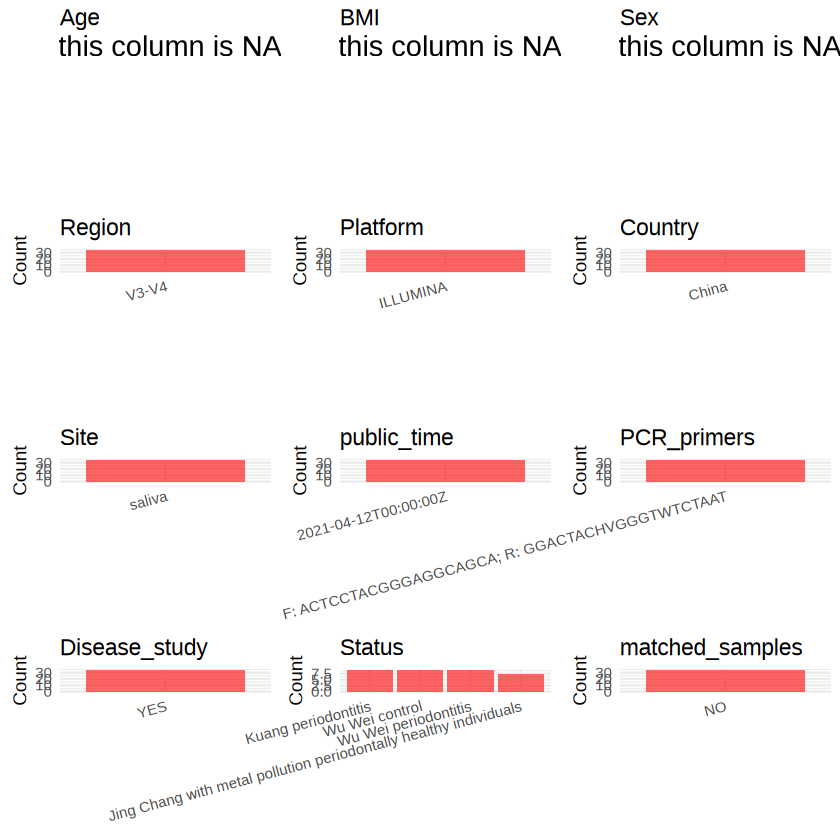

In [5]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)
create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    # Check if the column is all NA
    if (all(is.na(data[[col]]))) {
      # Create an empty plot with text indicating all NA
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      # Numeric variable: histogram
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      # Categorical variable: bar plot (remove NA values)
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  
  return(plots)
}
plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [6]:
## uniform the column order
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/PRJNA721290/metadata.csv", quote = F)